# Somalia Agriculture Data Visualization (2013–2023)

## Project Overview

This project explores recorded agricultural data for Somalia from 2013 to 2023, focusing on three crops: sorghum, maize (corn), and rice.

Using Python, Pandas, Matplotlib, and Seaborn, the analysis visualizes crop production, yield, and harvested area to identify patterns and changes over time.

## Objectives

- Compare total recorded production across the three crops.
- Examine annual production trends.
- Identify the highest and lowest recorded sorghum production.
- Analyze changes in crop yield and harvested area.
- Communicate key findings through clear visualizations and written interpretations.

## Tools and Technologies

- Python
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook / Google Colab

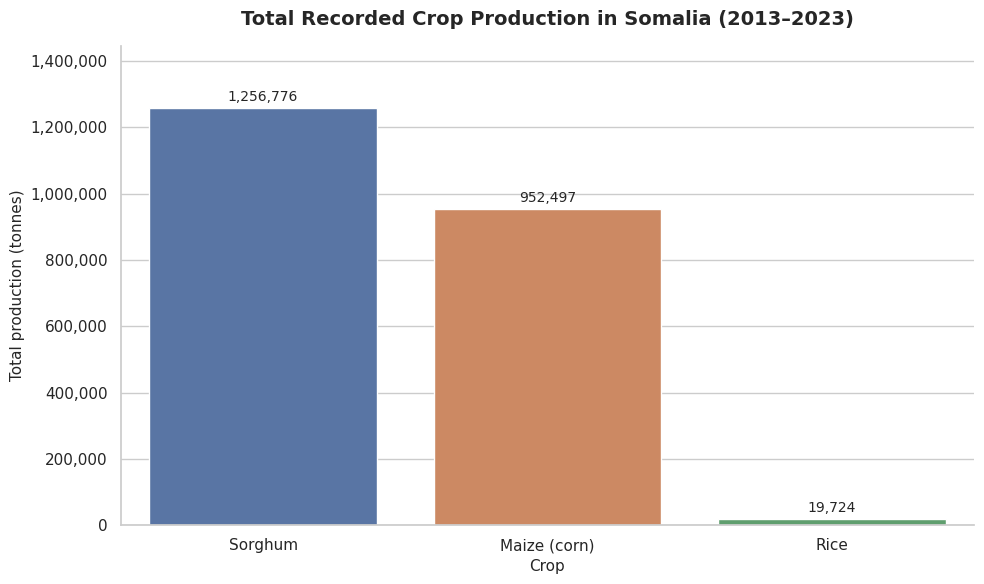

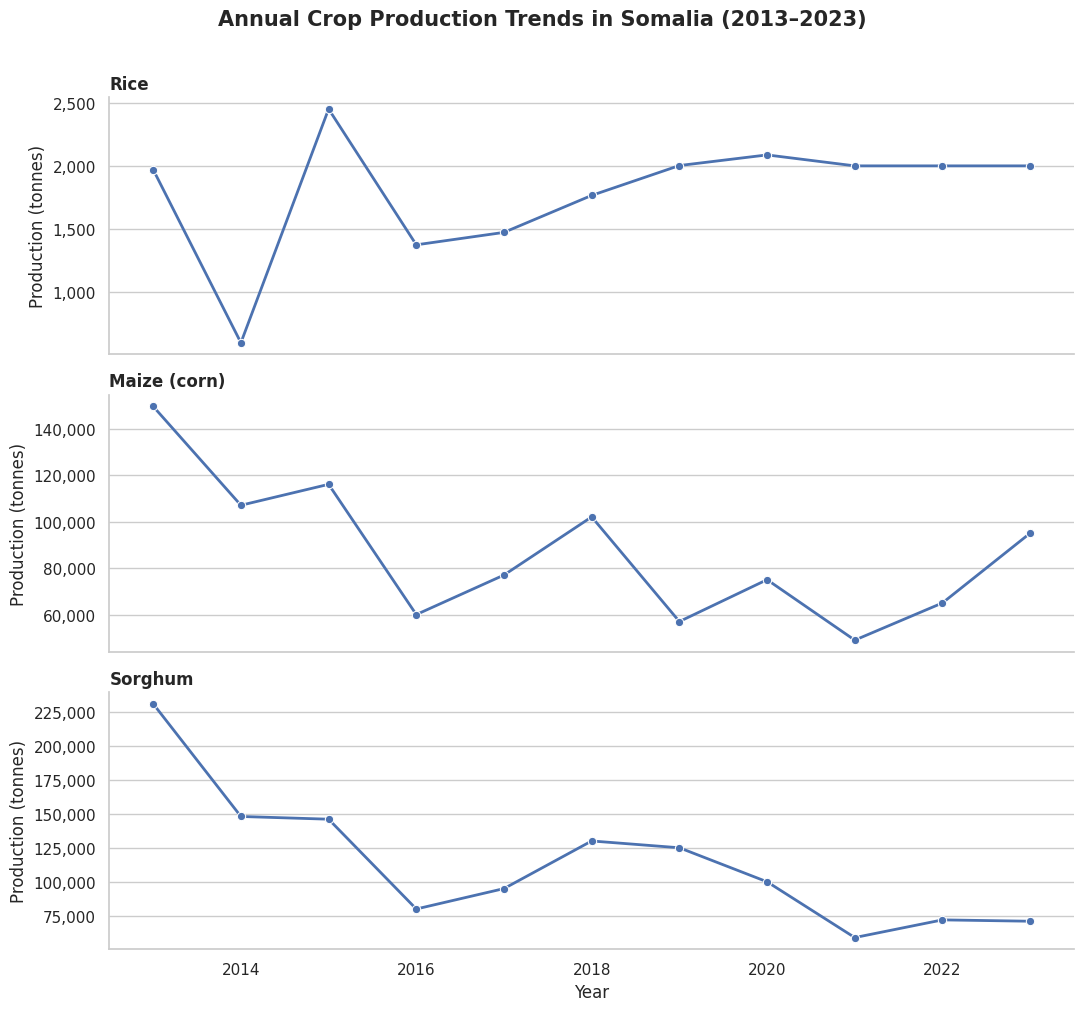

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import StrMethodFormatter

df = pd.read_excel("Somalia_Agriculture_EDA.xlsx")

production = df[df["Element"] == "Production"].copy()

sns.set_theme(style="whitegrid", context="notebook")

crop_totals = (
    production.groupby("Item")["Value"]
    .sum()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    x=crop_totals.index,
    y=crop_totals.values,
    hue=crop_totals.index,
    legend=False,
    palette="deep",
    ax=ax
)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{height:,.0f}",
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='center',
            xytext=(0, 8),
            textcoords='offset points',
            fontsize=10
        )

ax.set_title(
    "Total Recorded Crop Production in Somalia (2013–2023)",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Crop", fontsize=11)
ax.set_ylabel("Total production (tonnes)", fontsize=11)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_ylim(0, crop_totals.max() * 1.15)
ax.grid(axis="x", visible=False)

sns.despine()
plt.tight_layout()
plt.show()

crops = production["Item"].unique()

fig, axes = plt.subplots(
    nrows=len(crops),
    ncols=1,
    figsize=(11, 10),
    sharex=True
)

if len(crops) == 1:
    axes = [axes]

for ax, crop in zip(axes, crops):
    crop_data = production[production["Item"] == crop]

    sns.lineplot(
        data=crop_data,
        x="Year",
        y="Value",
        marker="o",
        linewidth=2,
        ax=ax
    )

    ax.set_title(crop, loc="left", fontweight="bold")
    ax.set_ylabel("Production (tonnes)")
    ax.yaxis.set_major_formatter(
        StrMethodFormatter("{x:,.0f}")
    )
    ax.grid(axis="x", visible=False)

axes[-1].set_xlabel("Year")

fig.suptitle(
    "Annual Crop Production Trends in Somalia (2013–2023)",
    fontsize=15,
    fontweight="bold",
    y=1.01
)

sns.despine()
plt.tight_layout()
plt.show()

### Interpretation: Crop Production Comparison and Annual Trends

The visualizations show differences in recorded agricultural production among sorghum, maize (corn), and rice in Somalia from 2013 to 2023. The total production comparison indicates that sorghum had the highest cumulative production over the period, followed by maize, while rice had substantially lower recorded production.

The annual production trends provide further insight into how production changed over time. Sorghum experienced a substantial decline from its high recorded level in 2013, reaching its lowest recorded production in 2021 before increasing slightly in the following years. Maize production also fluctuated throughout the period, while rice production remained considerably lower than that of the other two crops.

Together, these visualizations demonstrate that the three crops followed different production patterns. The findings highlight the importance of examining both cumulative production and annual changes when analyzing agricultural trends. However, the visualizations describe patterns in the recorded data and do not establish the causes of these changes.

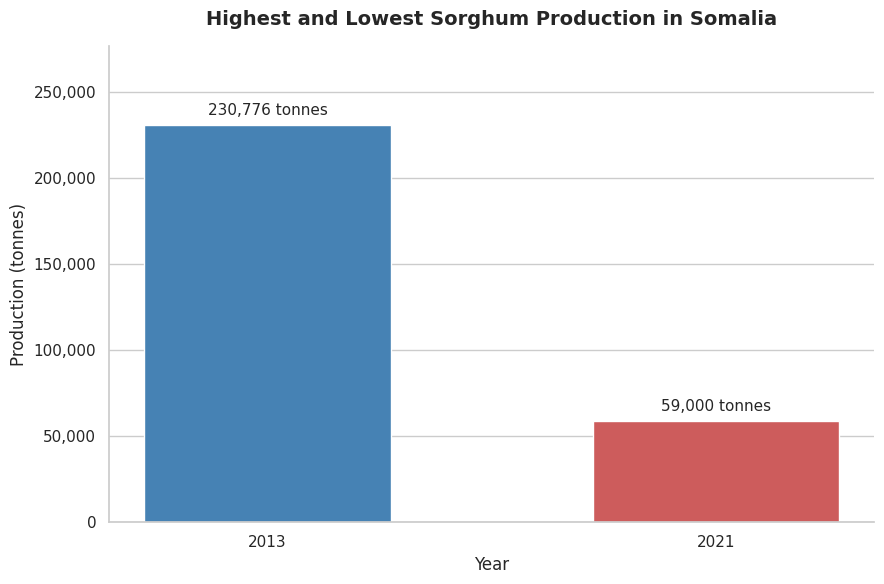

Highest production: 2013 — 230,776 tonnes
Lowest production: 2021 — 59,000 tonnes
Change from highest to lowest: -74.4%


In [ ]:

from matplotlib.ticker import StrMethodFormatter

sorghum = production[
    production["Item"].str.contains("Sorghum", case=False, na=False)
].copy()

highest = sorghum.loc[sorghum["Value"].idxmax()]
lowest = sorghum.loc[sorghum["Value"].idxmin()]

extremes = sorghum[
    sorghum["Year"].isin([highest["Year"], lowest["Year"]])
].sort_values("Year")

percentage_change = (
    (lowest["Value"] - highest["Value"]) / highest["Value"]
) * 100

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    extremes["Year"].astype(str),
    extremes["Value"],
    color=["steelblue", "indianred"],
    width=0.55
)

ax.bar_label(
    bars,
    labels=[f"{v:,.0f} tonnes" for v in extremes["Value"]],
    padding=5,
    fontsize=11
)

ax.set_title(
    "Highest and Lowest Sorghum Production in Somalia",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Year")
ax.set_ylabel("Production (tonnes)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_ylim(0, extremes["Value"].max() * 1.2)
ax.grid(axis="x", visible=False)

sns.despine()
plt.tight_layout()
plt.show()

print(f"Highest production: {highest['Year']:.0f} — "
      f"{highest['Value']:,.0f} tonnes")

print(f"Lowest production: {lowest['Year']:.0f} — "
      f"{lowest['Value']:,.0f} tonnes")

print(f"Change from highest to lowest: {percentage_change:.1f}%")


### Interpretation: Highest and Lowest Sorghum Production

The chart highlights the difference between the highest and lowest recorded sorghum production in Somalia during 2013–2023. Production reached its highest level in 2013 at **230,776 tonnes**, while the lowest level was recorded in 2021 at **59,000 tonnes**. This represents a decline of approximately **74.4%** from the highest to the lowest recorded value.

Although production increased slightly after 2021, it remained considerably below the 2013 peak by the end of the period. This comparison highlights the substantial variation in recorded sorghum production over the years and the importance of monitoring changes in agricultural output. However, the chart shows the size of the change; it does not identify the factors responsible for it.

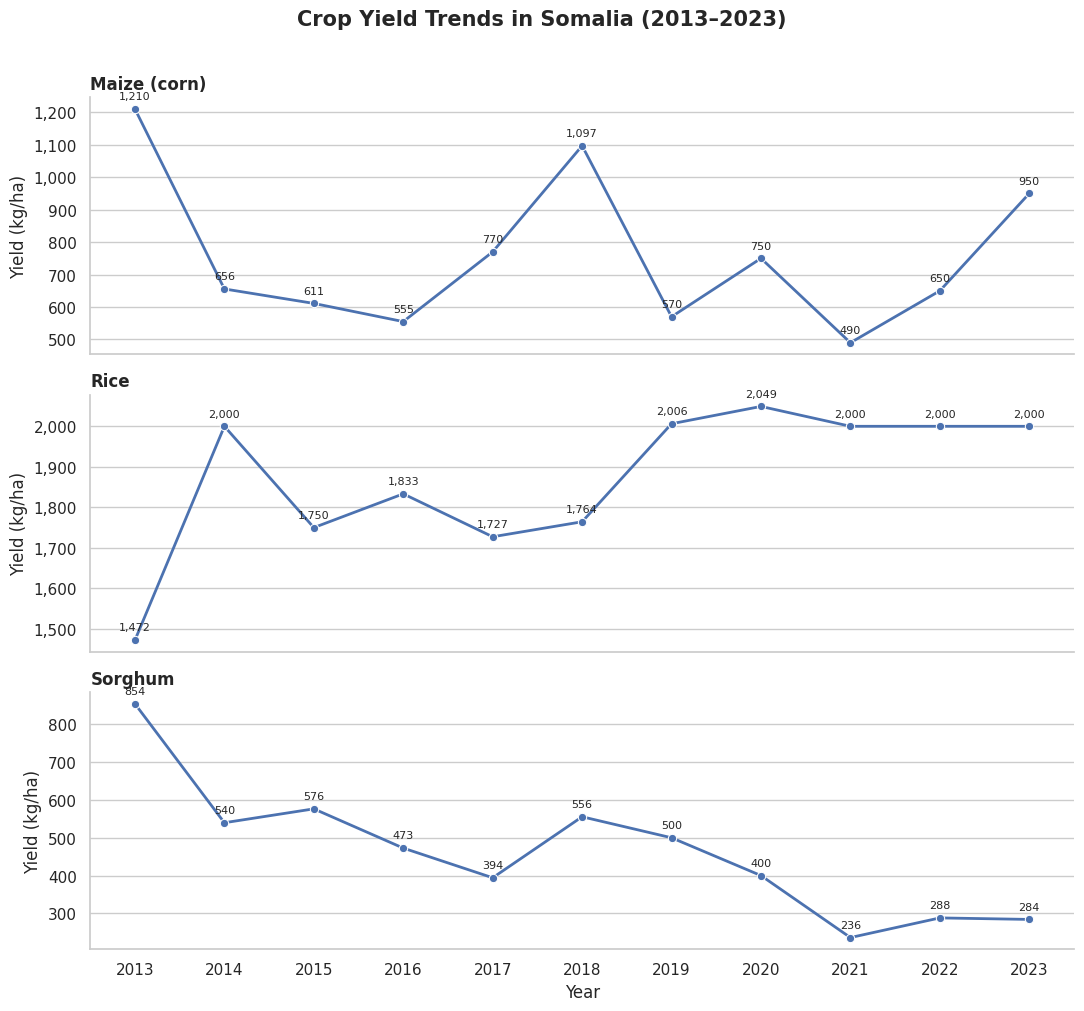

In [ ]:

from matplotlib.ticker import StrMethodFormatter

yield_data = df[
    df["Element"].str.contains("Yield", case=False, na=False)
].copy()

if yield_data.empty:
    print("No yield records found. Check the Element column.")
else:
    crops = sorted(yield_data["Item"].unique())

    fig, axes = plt.subplots(
        nrows=len(crops),
        ncols=1,
        figsize=(11, 10),
        sharex=True,
        squeeze=False
    )

    axes = axes.flatten()

    for ax, crop in zip(axes, crops):
        crop_data = (
            yield_data[yield_data["Item"] == crop]
            .sort_values("Year")
        )

        sns.lineplot(
            data=crop_data,
            x="Year",
            y="Value",
            marker="o",
            linewidth=2,
            markersize=6,
            ax=ax
        )

        for _, row in crop_data.iterrows():
            ax.annotate(
                f"{row['Value']:,.0f}",
                (row["Year"], row["Value"]),
                textcoords="offset points",
                xytext=(0, 7),
                ha="center",
                fontsize=8
            )

        ax.set_title(crop, loc="left", fontweight="bold")
        ax.set_ylabel("Yield (kg/ha)")
        ax.yaxis.set_major_formatter(
            StrMethodFormatter("{x:,.0f}")
        )
        ax.grid(axis="x", visible=False)

    axes[-1].set_xlabel("Year")
    axes[-1].set_xticks(sorted(yield_data["Year"].unique()))

    fig.suptitle(
        "Crop Yield Trends in Somalia (2013–2023)",
        fontsize=15,
        fontweight="bold",
        y=1.01
    )

    sns.despine()
    plt.tight_layout()
    plt.show()


### Interpretation: Crop Yield Trends

The chart illustrates changes in the recorded yield of sorghum, maize (corn), and rice in Somalia from 2013 to 2023. By displaying each crop separately, the visualization makes it easier to observe differences in yield patterns over time.

The trends indicate that sorghum yield declined substantially during the period, while maize yield also decreased but to a lesser extent. In contrast, rice yield increased over the same period. These differences suggest that the three crops experienced distinct yield patterns between 2013 and 2023.

Examining crop yield alongside production and harvested area helps provide a broader understanding of agricultural performance. However, these visualizations describe changes in the recorded data and do not establish the reasons behind them.

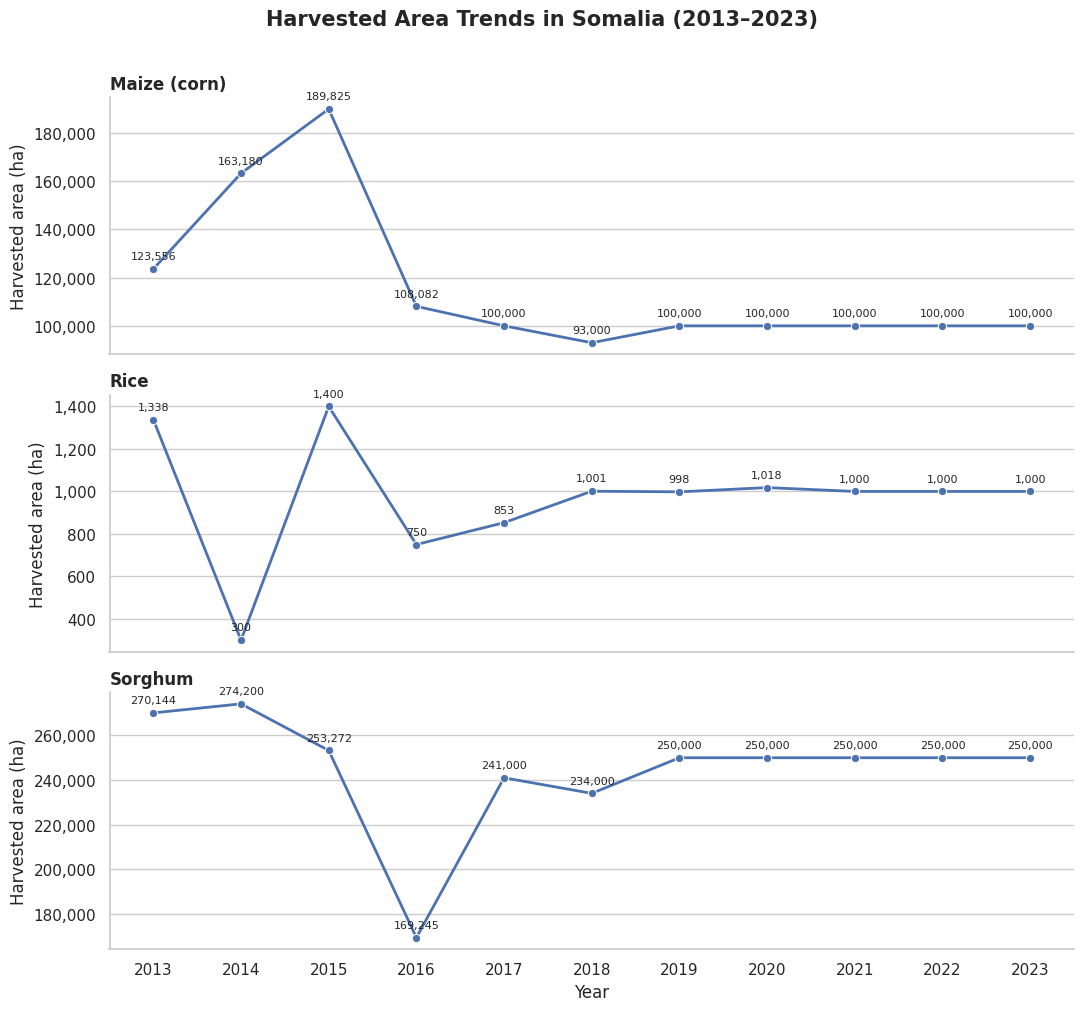

In [ ]:

from matplotlib.ticker import StrMethodFormatter
area_data = df[
    df["Element"].eq("Area harvested")
].copy()

if area_data.empty:
    print("No harvested area records found. Check the Element column.")

else:
    crops = sorted(area_data["Item"].unique())

    fig, axes = plt.subplots(
        nrows=len(crops),
        ncols=1,
        figsize=(11, 10),
        sharex=True,
        squeeze=False
    )

    axes = axes.flatten()

    for ax, crop in zip(axes, crops):
        crop_data = (
            area_data[area_data["Item"] == crop]
            .sort_values("Year")
        )

        sns.lineplot(
            data=crop_data,
            x="Year",
            y="Value",
            marker="o",
            linewidth=2,
            markersize=6,
            ax=ax
        )

        for _, row in crop_data.iterrows():
            ax.annotate(
                f"{row['Value']:,.0f}",
                (row["Year"], row["Value"]),
                textcoords="offset points",
                xytext=(0, 7),
                ha="center",
                fontsize=8
            )

        ax.set_title(crop, loc="left", fontweight="bold")
        ax.set_ylabel("Harvested area (ha)")
        ax.yaxis.set_major_formatter(
            StrMethodFormatter("{x:,.0f}")
        )
        ax.grid(axis="x", visible=False)

    axes[-1].set_xlabel("Year")
    axes[-1].set_xticks(
        sorted(area_data["Year"].unique())
    )

    fig.suptitle(
        "Harvested Area Trends in Somalia (2013–2023)",
        fontsize=15,
        fontweight="bold",
        y=1.01
    )

    sns.despine()
    plt.tight_layout()
    plt.show()


### Interpretation: Harvested Area Trends

The chart illustrates changes in the harvested area of sorghum, maize (corn), and rice in Somalia from 2013 to 2023, measured in hectares (ha). Presenting each crop separately makes it easier to compare changes in the land harvested for each crop over time.

The recorded data show that the harvested area for sorghum decreased slightly over the period, while maize experienced a more noticeable decline. Rice also showed a reduction in harvested area, despite an increase in its recorded yield over the same period.

These patterns highlight that changes in harvested area differed among the three crops. When considered alongside the production and yield charts, the visualization provides a broader picture of changes in Somalia's recorded agricultural activity. However, the chart describes trends in harvested land and does not establish the reasons behind these changes.

## Conclusion

This project explored recorded agricultural production, crop yield, and harvested area in Somalia from 2013 to 2023, focusing on sorghum, maize (corn), and rice. Using Python, Pandas, Matplotlib, and Seaborn, five visualizations were created to compare production levels, examine annual trends, identify the highest and lowest sorghum production, and investigate changes in yield and harvested area.

Overall, the visualizations show that agricultural trends differed across the three crops. Sorghum and maize experienced declines in recorded production and yield over the period, while rice yield increased. Harvested area also changed differently across crops.

These findings demonstrate the value of data visualization for identifying patterns and communicating agricultural trends. However, the analysis is descriptive and does not establish the causes of the observed changes. Further investigation using additional information, such as rainfall, drought conditions, and agricultural inputs, could help explain these patterns and support more informed agricultural planning.

## Data Source

The agricultural data used in this project was obtained from **FAOSTAT**, the Food and Agriculture Organization of the United Nations (FAO) statistical database. The analysis focuses on Somalia's recorded production, yield, and harvested area for sorghum, maize (corn), and rice from 2013 to 2023.

**Dataset:** Crop production, yield, harvested area (Global, National – Annual)  
**Source:** [FAOSTAT – Official Dataset Catalog](https://data.fao.org/catalog/iso/d24a448b-3b62-4c09-8c1d-4a39bb599876)  
**Country:** Somalia  
**Period analyzed:** 2013–2023  
**Date accessed:** 29 October 2026

The data was analyzed using Python, Pandas, Matplotlib, and Seaborn to explore crop production patterns, yield changes, and harvested area trends.